In [5]:
import sys 
import os
from tqdm import tqdm
import sglang as sgl
import json
from datetime import datetime
import supervision as sv
import cv2
import torch
import numpy as np
from transformers import LlavaNextProcessor, LlavaNextForConditionalGeneration, AutoTokenizer, AutoConfig
from captum.attr import visualization
import matplotlib.pyplot as plt

# Add the project root directory to sys.path
project_root = os.path.abspath('..')  # Adjust this path if needed
sys.path.append(project_root)

from utils import load_images_and_combine

2024-07-19 20:53:07.098591: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-07-19 20:53:07.126392: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-07-19 20:53:07.134778: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-07-19 20:53:07.157164: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-07-19 20:53:08.776528: W tensorflow/compiler/tf2

[07/19/24 20:53:12] WARNING  Your inference package version 0.12.1 is out of date! Please upgrade to ]8;id=977561;file:///usr/local/lib/python3.10/site-packages/inference/core/__init__.py\__init__.py]8;;\:]8;id=699219;file:///usr/local/lib/python3.10/site-packages/inference/core/__init__.py#35\35]8;;\
                             version 0.15.0 of inference for the latest features and bug fixes by                  
                             running `pip install --upgrade inference`.                                            

In [6]:
# load model
gpu_id = 1
# if error with flash-attn build in cd /workspace/home/flash-attention  $ pip install . --no-build-isolation
model_path = "llava-hf/llava-v1.6-mistral-7b-hf"
tokenizer_path = "llava-hf/llava-1.5-7b-hf"
processor_path = "llava-hf/llava-v1.6-mistral-7b-hf"
config = AutoConfig.from_pretrained(model_path, output_attentions=True)
model = LlavaNextForConditionalGeneration.from_pretrained(model_path, torch_dtype=torch.float16, low_cpu_mem_usage=True, config=config).to(f'cuda:{gpu_id}') 
tokenizer = AutoTokenizer.from_pretrained(tokenizer_path)
processor = LlavaNextProcessor.from_pretrained(processor_path)

Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

Special tokens have been added in the vocabulary, make sure the associated word embeddings are fine-tuned or trained.
Special tokens have been added in the vocabulary, make sure the associated word embeddings are fine-tuned or trained.


In [7]:
model.gradient_checkpointing_enable()
model.is_gradient_checkpointing 


True

In [8]:
def image_qa(image_file, question):
    prompt = "[INST] <image>\n{question} [/INST]"
    if isinstance(image_file, str):
        image = cv2.imread(image_file)
    else:
        image = image_file

    inputs = processor(text=prompt, images=image, return_tensors="pt").to(f'cuda:{gpu_id}')

    # Generate
    outputs = model.generate(**inputs, max_length=150, output_attentions=True, return_dict_in_generate=True)
    generated_ids = outputs.sequences
    output_text = processor.batch_decode(generated_ids, skip_special_tokens=True, clean_up_tokenization_spaces=True)[0]
    attentions = outputs.attentions

    return output_text, attentions

In [9]:
# load images
num_imgs = 1
confounder_dir="horse_watermark"
no_confounder_dir="horse_no_watermark"
dataset_dir="Pascal_VOC07"
images = load_images_and_combine(dir_path=f"/workspace/home/data/{dataset_dir}", confounder_dir=confounder_dir, no_confounder_dir=no_confounder_dir, num_imgs=num_imgs)


chat_template = "chat-template vicuna_v1.1"

# output file
data_dict = {}
data_dict['model_path'] = model_path
data_dict['tokenizer_path'] = tokenizer_path
data_dict['chat_template'] = chat_template
data_dict['num_imgs'] = num_imgs

In [10]:
def attention_vis(attention, input_image):#target_output, attention_map):
    # Backward pass
    #model.zero_grad()
    #target_output.backward()

    # For simplicity, let's take the last layer's attention and the first head
    attention_last_layer = attention[-1][0][0][0].detach().cpu().numpy().astype(np.uint8)  # (seq_len, seq_len)
    print("attention_last_layer", attention_last_layer.shape)

    # Normalize the attention scores
    attention_scores = attention_last_layer / attention_last_layer.max()

    # Assuming you want to visualize the attention scores on the image
    # First, resize the attention scores to match the image dimensions
    image_height, image_width, _ = input_image.shape
    seq_len = attention_scores.shape[0]
    print("seq_len", seq_len)
    print("image_height", image_height)
    print("image_width", image_width)

    # Depending on the model, you might need to separate the text and image tokens.
    # Here, I'm assuming the first 'n' tokens correspond to the image, and the rest to text.

    image_token_len = 915  #??? Set this to the correct length of image tokens
    text_token_len = seq_len - image_token_len

    # Resize the attention map to the image size (assuming a square image for simplicity)
    attention_image = attention_scores[:image_token_len, :image_token_len]
    attention_image_resized = cv2.resize(attention_image, (image_width, image_height))

    # Normalize the resized attention map
    attention_image_resized /= attention_image_resized.max()

    # Overlay the attention map on the image
    overlay_image = input_image.copy()
    heatmap = cv2.applyColorMap(np.uint8(255 * attention_image_resized), cv2.COLORMAP_JET)
    overlay_image = cv2.addWeighted(overlay_image, 0.6, heatmap, 0.4, 0)

    # Plot the overlay image
    plt.figure(figsize=(10, 10))
    plt.imshow(cv2.cvtColor(overlay_image, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    plt.title('Attention Overlay')
    plt.show()

In [11]:
def run_inference(images, num_imgs, question1, question2=None, data_dict=None):
    correct_classified = 0
    false_classified = 0
    more_than_one_word = 0
    num_yes_patch = 0
    num_no_no_patch = 0
    num_yes = 0
    num_no = 0

    output_dict = None
    if data_dict is not None:
        if question2 is None:
            data_dict['prompt']= question1
        else:
            data_dict['question1']= question1
            data_dict['question2']= question2
        output_dict = {}


    print("-----------------------------------------\n")
    
    print(question1)
    if question2 is not None:
        print('\n', question2)
    
    for i, image_dict in enumerate(tqdm(images[:num_imgs])):
        image = image_dict['image']
        meta = image_dict['meta']

     
        ## display image
        #imageUrl = meta['file_path']
        #image = Image.open(imageUrl).convert("RGB")
        #plt.figure(figsize=(8, 3))
        #plt.imshow(image)
        
        
        # image
        image_path = meta['file_path']
        
        sv.plot_image(cv2.imread(image_path), (7,7))
        

        #response
        response, attentions = image_qa(image_path, question1)
        print(len(question1.split()))

        print("Attention: ", attentions)
        print("Attention len: ", len(attentions))
        print("Attention[0] len: ", len(attentions[0]))
        for i in range(len(attentions)):
            #for j in range(len(attentions[i])):
            print(f"Attention[{i}][0] shape: ", attentions[i][0].shape)
        print("Attention tensor shape: ", attentions[0][0].shape)
        print("response len: ", len(response.split()))
        print("Response: ", response)

        attention_vis(attentions, cv2.imread(image_path))

    
        if response in {"yes", "yes."}:
            #print("yes")
            num_yes += 1
            if meta[confounder_dir]:
                correct_classified += 1
                num_yes_patch += 1
                #print("correct")
            else:
                false_classified += 1
                #print("false")
    
        elif response in {"no", "no."}:
            #print("no")
            
            num_no += 1
            if meta[confounder_dir]:
                false_classified += 1
                #print("false")
            else:
                correct_classified += 1
                num_no_no_patch +=1
                #print("correct")
        else:
            #print("No yes or no!")
            more_than_one_word += 1

        # save data
        #if output_dict is not None:
        #    img_output_dict = {}
        #    
        #    if question2 is None:
        #        img_output_dict['answer'] =  state["answer"]
        #    else:
        #        img_output_dict['img_meta'] = image_dict['meta']
        #        img_output_dict['explanation'] = state["explanation"]
        #        img_output_dict['is_patch'] = state["output"]
        #    output_dict[f'img_{i}'] = img_output_dict


    acc = correct_classified/(num_imgs - more_than_one_word)
    
    print("\nAccuracy: ",acc)
    print("correct classified: ", correct_classified,"\nfalse classified: ", false_classified, 
          "\nNumber yes: ", num_yes, "\nNumber no: ", num_no, "\nNeither yes or no: ", more_than_one_word,
          "\nNumber True positives: ", num_yes_patch, "\nNumber True negatives: ", num_no_no_patch,
          "\nnum images: ", num_imgs)
    print("\n-----------------------------------------\n\n")

    # save data
    if data_dict is not None:
        data_dict['accuracy'] = acc
        data_dict['correct_classified'] = correct_classified
        data_dict['false_classified'] = false_classified
        data_dict['num_yes'] = num_yes
        data_dict['num_no'] = num_no
        data_dict['more_than_one_word'] = more_than_one_word
        data_dict['true_positive'] = num_yes_patch
        data_dict['true_negative'] = num_no_no_patch
        data_dict['outputs']=output_dict

        # Mkdir if not existent
        path=f"/home/outputfiles/{dataset_dir}"
        os.makedirs(path, exist_ok=True)
        
        # Generate a timestamp
        timestamp = datetime.now().strftime("%Y%m%dT%H%M%S")

        # Create a filename with the timestamp
        filename = f"{path}/llava_output_{str(correct_classified)}_{timestamp}.json"
        
        with open(filename, 'w', encoding='utf-8') as f:
            json.dump(data_dict, f, indent=4)
        

-----------------------------------------

The image shows an image of a horse. On some images there is a overlayed text. Please think about if you can see a overlayed text like for example a signature, or timestamp in the image or not. Also consider why it might seem like an text added in postproduction or a text of the background/the scene, e.g., a sign. Is there such an overlayed text? Answer with one word of the options [yes, no]

 Can you tell me, considering your explanation, if you can see an overlayed text on the image or not? Answer with one word of the options [yes, no].


  0%|          | 0/2 [00:00<?, ?it/s]

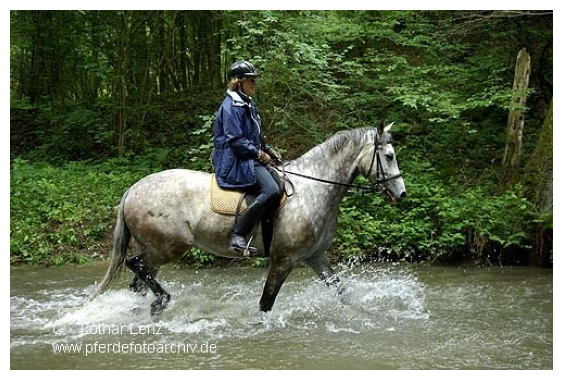

Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.
MistralModel is using MistralSdpaAttention, but `torch.nn.functional.scaled_dot_product_attention` does not support `output_attentions=True`. Falling back to the manual attention implementation, but specifying the manual implementation will be required from Transformers version v5.0.0 onwards. This warning can be removed using the argument `attn_implementation="eager"` when loading the model.


75
Attention:  ((tensor([[[[1.0000e+00, 0.0000e+00, 0.0000e+00,  ..., 0.0000e+00, 0.0000e+00, 0.0000e+00],
          [9.8193e-01, 1.8280e-02, 0.0000e+00,  ..., 0.0000e+00, 0.0000e+00, 0.0000e+00],
          [9.5508e-01, 3.3966e-02, 1.1055e-02,  ..., 0.0000e+00, 0.0000e+00, 0.0000e+00],
          ...,
          [4.8096e-01, 4.4537e-04, 1.5247e-04,  ..., 1.5976e-02, 0.0000e+00, 0.0000e+00],
          [3.3667e-01, 3.9029e-04, 1.6499e-04,  ..., 1.1978e-02, 3.9444e-03, 0.0000e+00],
          [3.6328e-01, 6.5374e-04, 3.3069e-04,  ..., 6.2523e-03, 4.2343e-03, 1.6068e-02]],

         [[1.0000e+00, 0.0000e+00, 0.0000e+00,  ..., 0.0000e+00, 0.0000e+00, 0.0000e+00],
          [9.8486e-01, 1.5274e-02, 0.0000e+00,  ..., 0.0000e+00, 0.0000e+00, 0.0000e+00],
          [4.5093e-01, 3.6157e-01, 1.8762e-01,  ..., 0.0000e+00, 0.0000e+00, 0.0000e+00],
          ...,
          [3.7573e-01, 5.0068e-04, 1.6892e-04,  ..., 1.0765e-02, 0.0000e+00, 0.0000e+00],
          [1.3464e-01, 4.7660e-04, 2.5249e-04,  ...

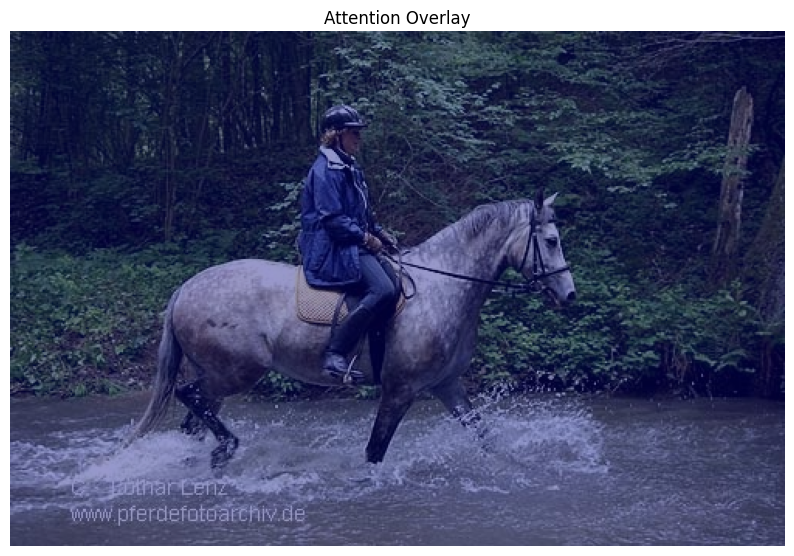

 50%|█████     | 1/2 [00:22<00:22, 22.90s/it]

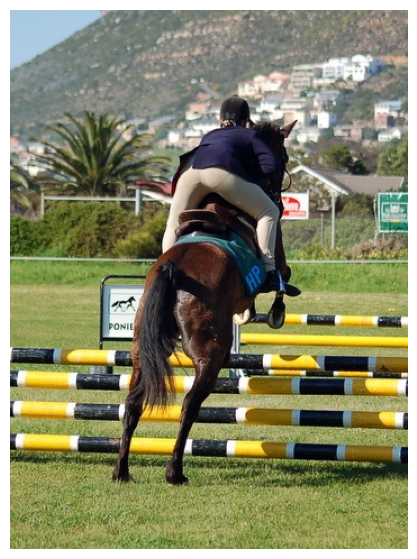

Setting `pad_token_id` to `eos_token_id`:2 for open-end generation.


75
Attention:  ((tensor([[[[1.0000e+00, 0.0000e+00, 0.0000e+00,  ..., 0.0000e+00, 0.0000e+00, 0.0000e+00],
          [9.8193e-01, 1.8280e-02, 0.0000e+00,  ..., 0.0000e+00, 0.0000e+00, 0.0000e+00],
          [9.5508e-01, 3.3966e-02, 1.1063e-02,  ..., 0.0000e+00, 0.0000e+00, 0.0000e+00],
          ...,
          [4.4458e-01, 4.6015e-04, 1.3876e-04,  ..., 1.5121e-02, 0.0000e+00, 0.0000e+00],
          [3.0005e-01, 3.6740e-04, 1.9288e-04,  ..., 1.0727e-02, 3.5305e-03, 0.0000e+00],
          [3.0469e-01, 6.8521e-04, 4.6086e-04,  ..., 5.1804e-03, 3.5057e-03, 1.3290e-02]],

         [[1.0000e+00, 0.0000e+00, 0.0000e+00,  ..., 0.0000e+00, 0.0000e+00, 0.0000e+00],
          [9.8486e-01, 1.5274e-02, 0.0000e+00,  ..., 0.0000e+00, 0.0000e+00, 0.0000e+00],
          [4.5093e-01, 3.6157e-01, 1.8762e-01,  ..., 0.0000e+00, 0.0000e+00, 0.0000e+00],
          ...,
          [3.3472e-01, 3.3331e-04, 8.2791e-05,  ..., 9.4452e-03, 0.0000e+00, 0.0000e+00],
          [1.1047e-01, 4.0889e-04, 1.8752e-04,  ...

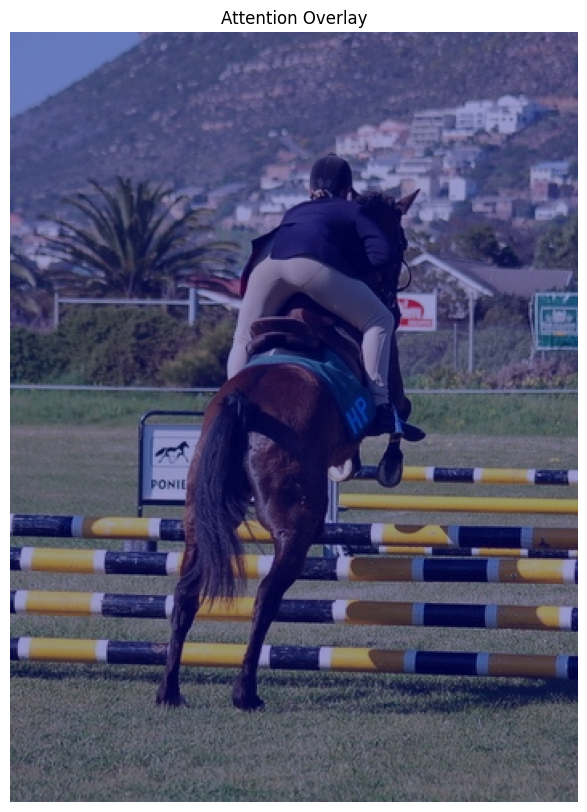

100%|██████████| 2/2 [00:43<00:00, 21.71s/it]


Accuracy:  0.0
correct classified:  0 
false classified:  0 
Number yes:  0 
Number no:  0 
Neither yes or no:  2 
Number True positives:  0 
Number True negatives:  0 
num images:  100

-----------------------------------------




In [12]:
#question1 = "The image shows an image of a horse. On some images there is a watermark. Please explain if you can see a watermark in the image or not. Also explain what might seem like a watermark is just a text of the background, e.g., a sign."
#"The image shows an image of a horse. On some images there is a overlayed text. Please explain if you can see a overlayed text like for example a signature, or timestamp in the image or not. Also explain why it might seem like an text added in postproduction or a text of the background/the scene, e.g., a sign."

#question2 = "Can you tell me, considering your explanation, if you can see a watermark on the image or not? Answer with one word of the options [yes, no]."

question1 = "The image shows an image of a horse. On some images there is a overlayed text. Please think about if you can see a overlayed text like for example a signature, or timestamp in the image or not. Also consider why it might seem like an text added in postproduction or a text of the background/the scene, e.g., a sign. Is there such an overlayed text? Answer with one word of the options [yes, no]"
question2 = "Can you tell me, considering your explanation, if you can see an overlayed text on the image or not? Answer with one word of the options [yes, no]."


run_inference(images, num_imgs=100, question1=question1, question2=question2, data_dict=data_dict)